In [2]:
import pandas as pd
import statsmodels.formula.api as sm
import matplotlib.pyplot as plt

In [7]:
campaigns = pd.read_csv('../data/northbound_campaigns.csv')
campaigns.tail()

,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue
436,NB0437,2025-12-15,Video,0,4389.91,403864,3023,46,4609.02
437,NB0438,2025-12-22,Search,0,5827.12,296436,12601,574,51636.55
438,NB0439,2025-12-29,Search,0,4510.66,188606,7213,497,46921.79
439,NB0440,2025-12-29,Social,0,3504.61,516602,5124,117,11741.34
440,NB0441,2025-12-29,Display,0,3191.70,1177663,5167,84,7604.06


In [8]:
campaigns['impressions_k'] = campaigns['impressions'] / 1000
campaigns.tail()

,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue,impressions_k
436,NB0437,2025-12-15,Video,0,4389.91,403864,3023,46,4609.02,403.864
437,NB0438,2025-12-22,Search,0,5827.12,296436,12601,574,51636.55,296.436
438,NB0439,2025-12-29,Search,0,4510.66,188606,7213,497,46921.79,188.606
439,NB0440,2025-12-29,Social,0,3504.61,516602,5124,117,11741.34,516.602
440,NB0441,2025-12-29,Display,0,3191.70,1177663,5167,84,7604.06,1177.663


In [9]:
search = campaigns.loc[campaigns['channel'] == 'Search']

In [11]:
search_model = sm.ols('conversions ~ impressions_k', data=search).fit()

In [12]:
search_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            conversions   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     444.9
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           1.38e-46
Time:                        14:12:37   Log-Likelihood:                -893.25
No. Observations:                 151   AIC:                             1790.
Df Residuals:                     149   BIC:                             1797.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         5.0398     16.835      0.299      0.765     -28.225      38.305
impressions_k     1.5406      0.073     21.092      0.000       1.396       1.685
==============================================================================
Omnibus:                        3.102   Durbin-Watson:                   1.357
Prob(Omnibus):                  0.212   Jarque-Bera (JB):                3.114
Skew:                           0.342   Prob(JB):                        0.211
Kurtosis:                       2.837   Cond. No.                         528.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Q: Suppose we estimate a 95% confidence bound for expected sales (conversion), given that we run a campaign with 500,000 impressions.

A: Recall that we can use the model to estimate expected conversions by substituting a value for impressions into the regression function:
E[Y|x=500] = 5.0398 + 1.5406*500 

Note that we *cannot* simply substitute upper and lower confidence bounds for \beta_0 and \beta_1 into this expression. The reason is that these estimate are not independent - and their correlation influences the variance of the forecast. So adding does *not* work.

Solution: use .get_prediction() method in statsmodels


In [14]:
predictor_data = pd.DataFrame({'impressions_k': [500]})
predictor_data

,impressions_k
0,500


In [15]:
search_model.get_prediction(predictor_data).summary_frame(alpha=0.5)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,775.361178,22.605189,760.076908,790.645448,712.413145,838.309211


The first number is the point forecast - the actual expected sales given 500k of impressions:

E[Y|x=500] = 5.04 + 1.54*500 = 775.04

mean_ci_lower and the mean_ci_upper define the 95% confidence bounds for the forecast -- so this tells us that with 95% probability, running a search campaign with 500k impressions will translate into at least 775 units sold, and at most 820 units sold.

In [17]:
search['impressions_cost'] = search['spend'] / search['impressions']

In [18]:
search[['impressions_cost']].tail()

,impressions_cost
427,0.026290
431,0.027013
434,0.024385
437,0.019657
438,0.023916


In [19]:
search[['impressions_cost']].describe()

,impressions_cost
count,151.000000
mean,0.024419
std,0.002952
min,0.017358
25%,0.022725
50%,0.024257
75%,0.026190
max,0.033127


array([[<Axes: title={'center': 'impressions_cost'}>]], dtype=object)

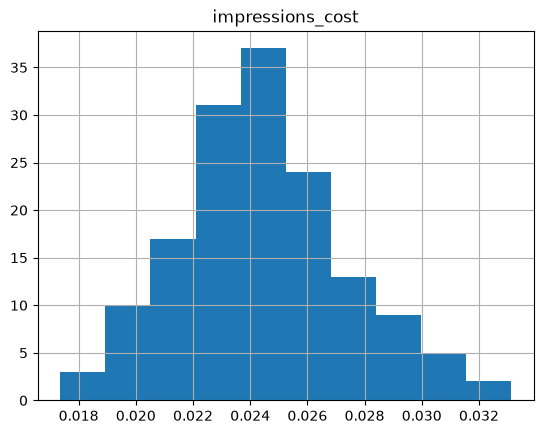

In [20]:
search[['impressions_cost']].hist()

In [21]:
# estimate avg cost per 1,000 search impressions
search_impressions_cost = search['spend'].sum() / search['impressions_k'].sum()

In [22]:
print(search_impressions_cost)

24.2290763531843


In [23]:
print(500*search_impressions_cost)

12114.53817659215


Suppose that we want to estimate with 95% confidence, the amount of money  it would take to generate 1 sale in a campaign with 500k impressions. We can do that by taking the ratio of campaign cost to unit sold to get the per-unit sold economic:

In [25]:
search_campaign_sales_cost_upper = (500*search_impressions_cost) / 730
search_campaign_sales_cost_lower = (500*search_impressions_cost) / 820
print('When running a search campaign, we can expect to spend between ', search_campaign_sales_cost_lower, ' and ', search_campaign_sales_cost_upper, ' dollars.')

When running a search campaign, we can expect to spend between  14.773827044624573  and  16.59525777615363  dollars.


In [27]:
campaigns['channel'].unique()

<StringArray>
['Social', 'Search', 'Display', 'Video']
Length: 4, dtype: str

In [28]:
video = campaigns.loc[campaigns['channel'] == 'Video']
video.tail()

,campaign_id,week_start,channel,discount_offer,spend,impressions,clicks,conversions,revenue,impressions_k
415,NB0416,2025-10-27,Video,0,4338.61,378108,2602,43,3955.89,378.108
423,NB0424,2025-11-17,Video,0,7278.20,498006,4584,79,6935.09,498.006
430,NB0431,2025-12-01,Video,0,4893.03,370273,3086,55,5073.51,370.273
433,NB0434,2025-12-08,Video,0,5719.27,473687,3672,84,7720.81,473.687
436,NB0437,2025-12-15,Video,0,4389.91,403864,3023,46,4609.02,403.864


In [39]:
campaigns_data_by_channel = {'search': search, 'model': search_model(),
                             'video': video}

TypeError: 'RegressionResultsWrapper' object is not callable

In [40]:
campaigns_data_by_channel['search']['model'].summary()

KeyError: 'model'

In [41]:
channels = campaigns['channel'].unique()
print(channels)

<StringArray>
['Social', 'Search', 'Display', 'Video']
Length: 4, dtype: str


In [48]:
for channel in channels:
    rows = campaigns.loc[campaigns['channel'] == channel]
    fit = sm.ols('conversions ~ impressions_k', data=rows).fit()
    conversions_forecast = fit.get_prediction(pd.DataFrame({
        'impressions_k': [500]
    })).summary_frame(alpha=0.5)
    # print(conversions_forecast)
    cost_per_thousand_impression = rows['spend'].sum() / rows['impressions_k'].sum()
    cost_to_sell_one_unit = (cost_per_thousand_impression * 500) / conversions_forecast['mean']
    print('Using the ', channel, 'it costs us ', cost_to_sell_one_unit, ' to sell one unit')

Using the  Social it costs us  0    33.905505
Name: mean, dtype: float64  to sell one unit
Using the  Search it costs us  0    15.624381
Name: mean, dtype: float64  to sell one unit
Using the  Display it costs us  0    60.76413
Name: mean, dtype: float64  to sell one unit
Using the  Video it costs us  0    104.256274
Name: mean, dtype: float64  to sell one unit
